In [ ]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


**Copie du dossier dataset vers un autre emplacement pour sauvegarde**

In [ ]:
"""
Copie complète d'un dossier (dataset) vers un autre emplacement
dans Google Drive, en conservant toute l'arborescence et les
métadonnées des fichiers.
"""

import shutil
from pathlib import Path

# ============================================================
# 1. CONFIGURATION — à adapter
# ============================================================
SOURCE_DIR = Path("/content/drive/MyDrive/test_doctorat/univ_misa/dataset")
DEST_DIR   = Path("/content/drive/MyDrive/test_doctorat/univ_misa/dataset_backup")

# Si True : écrase le contenu existant de DEST_DIR s'il existe déjà.
# Si False : refuse de copier si DEST_DIR existe déjà (sécurité).
OVERWRITE = False

# ============================================================
# 2. Vérifications préalables
# ============================================================
if not SOURCE_DIR.exists():
    raise FileNotFoundError(f"Le dossier source est introuvable : {SOURCE_DIR}")

if DEST_DIR.exists():
    if OVERWRITE:
        print(f"⚠️  Le dossier destination existe déjà et va être écrasé : {DEST_DIR}")
        shutil.rmtree(DEST_DIR)
    else:
        raise FileExistsError(
            f"Le dossier destination existe déjà : {DEST_DIR}\n"
            f"Passez OVERWRITE=True si vous voulez vraiment l'écraser, "
            f"ou choisissez un autre chemin de destination."
        )

# ============================================================
# 3. Copie récursive
# ============================================================
print(f"Copie en cours de :\n  {SOURCE_DIR}\nvers :\n  {DEST_DIR}\n")

shutil.copytree(SOURCE_DIR, DEST_DIR)

# ============================================================
# 4. Vérification post-copie (comptage des fichiers)
# ============================================================
n_source = sum(1 for _ in SOURCE_DIR.rglob("*") if _.is_file())
n_dest = sum(1 for _ in DEST_DIR.rglob("*") if _.is_file())

print(f"Fichiers dans le dossier source      : {n_source}")
print(f"Fichiers dans le dossier destination : {n_dest}")

if n_source == n_dest:
    print("- Copie réussie — le nombre de fichiers correspond.")
else:
    print("x ATTENTION : le nombre de fichiers ne correspond pas, vérifiez la copie.")

Copie en cours de :
  /content/drive/MyDrive/test_doctorat/univ_misa/dataset
vers :
  /content/drive/MyDrive/test_doctorat/univ_misa/dataset_backup

Fichiers dans le dossier source      : 627
Fichiers dans le dossier destination : 627
- Copie réussie — le nombre de fichiers correspond.


# Script de redistribution stratifiée (par classe) d'un dataset YOLO entre les dossiers train / val / test.

In [ ]:
"""
Script de redistribution stratifiée (par classe) d'un dataset YOLO
entre les dossiers train / val / test.

Prérequis de structure attendue sous ROOT_DIR, par exemple :
  ROOT_DIR/
    train/images/*.jpg  train/labels/*.txt
    val/images/*.jpg    val/labels/*.txt
    test/images/*.jpg   test/labels/*.txt

⚠️ IMPORTANT : ce script DÉPLACE des fichiers. Faites une copie de
sauvegarde de votre dataset avant de l'exécuter avec DRY_RUN=False.
"""

import random
import shutil
from pathlib import Path
from collections import defaultdict

# ============================================================
# 1. CONFIGURATION — à adapter
# ============================================================
ROOT_DIR = Path("/content/drive/MyDrive/test_doctorat/univ_misa/dataset")

SPLIT_RATIOS = {
    "train": 0.65,
    "val":   0.15,
    "test":  0.20,
}

IMG_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
SEED = 42
DRY_RUN = False   # <-- passez à False uniquement après avoir vérifié le rapport ci-dessous

random.seed(SEED)
assert abs(sum(SPLIT_RATIOS.values()) - 1.0) < 1e-6, "Les ratios doivent sommer à 1.0"

# ============================================================
# 2. Découverte des dossiers existants et collecte des fichiers
# ============================================================
existing_splits = [s for s in ["train", "val", "test"]
                    if (ROOT_DIR / s / "images").exists()]
print(f"Dossiers de split détectés : {existing_splits}")

# image_path -> {"label": label_path_or_None, "classes": set(int), "orig_split": str}
all_files = {}

for split in existing_splits:
    images_dir = ROOT_DIR / split / "images"
    labels_dir = ROOT_DIR / split / "labels"

    for img_path in sorted(images_dir.rglob("*")):
        if img_path.suffix.lower() not in IMG_EXTENSIONS:
            continue
        label_path = labels_dir / img_path.with_suffix(".txt").name
        classes_in_image = set()

        if label_path.exists() and label_path.stat().st_size > 0:
            with open(label_path, "r") as lf:
                for line in lf:
                    line = line.strip()
                    if line:
                        classes_in_image.add(int(line.split()[0]))

        all_files[img_path] = {
            "label": label_path if label_path.exists() else None,
            "classes": classes_in_image,          # ensemble vide = background
            "orig_split": split,
        }

print(f"Total images collectées (tous splits confondus) : {len(all_files)}")

# ============================================================
# 3. Regroupement par classe (une image peut apparaître dans
#    plusieurs classes — on traite les classes les plus rares
#    en premier pour préserver au mieux leur équilibre)
# ============================================================
images_by_class = defaultdict(list)
background_images = []

for img_path, info in all_files.items():
    if info["classes"]:
        for cls in info["classes"]:
            images_by_class[cls].append(img_path)
    else:
        background_images.append(img_path)

# Tri des classes : la plus rare d'abord (moins de marge de manœuvre)
classes_sorted = sorted(images_by_class.keys(), key=lambda c: len(images_by_class[c]))

assigned_split = {}  # img_path -> nouveau split

def assign_pool(pool, ratios):
    """Répartit une liste d'images (déjà mélangée) selon les ratios donnés,
    en ne touchant pas aux images déjà assignées."""
    pool = [p for p in pool if p not in assigned_split]
    random.shuffle(pool)
    n = len(pool)
    n_test = round(n * ratios["test"])
    n_val = round(n * ratios["val"])
    # Le train récupère le reste pour garantir que la somme == n
    n_train = n - n_test - n_val

    idx = 0
    for split_name, count in [("test", n_test), ("val", n_val), ("train", n_train)]:
        for img_path in pool[idx: idx + count]:
            assigned_split[img_path] = split_name
        idx += count

# 3a. Classes d'objets, de la plus rare à la plus fréquente
for cls in classes_sorted:
    assign_pool(images_by_class[cls], SPLIT_RATIOS)

# 3b. Images "background" (sans annotation), réparties selon le même ratio global
assign_pool(background_images, SPLIT_RATIOS)

# Sécurité : toute image qui n'aurait pas été traitée (ne devrait pas arriver)
for img_path in all_files:
    if img_path not in assigned_split:
        assign_pool([img_path], SPLIT_RATIOS)

# ============================================================
# 4. Rapport avant déplacement
# ============================================================
print("\n" + "=" * 70)
print("RAPPORT DE RÉPARTITION PRÉVUE (par classe, compte en IMAGES)")
print("=" * 70)
header = f"{'Classe':<10}{'Train':>10}{'Val':>10}{'Test':>10}{'Total':>10}"
print(header)

report = defaultdict(lambda: defaultdict(int))
for cls in classes_sorted:
    for img_path in images_by_class[cls]:
        report[cls][assigned_split[img_path]] += 1

for cls in classes_sorted:
    r = report[cls]
    total = sum(r.values())
    print(f"{cls:<10}{r.get('train',0):>10}{r.get('val',0):>10}{r.get('test',0):>10}{total:>10}")

bg_report = defaultdict(int)
for img_path in background_images:
    bg_report[assigned_split[img_path]] += 1
print(f"{'bg':<10}{bg_report.get('train',0):>10}{bg_report.get('val',0):>10}{bg_report.get('test',0):>10}{sum(bg_report.values()):>10}")

total_per_split = defaultdict(int)
for s in assigned_split.values():
    total_per_split[s] += 1
print("-" * 70)
print(f"{'TOTAL':<10}{total_per_split.get('train',0):>10}{total_per_split.get('val',0):>10}{total_per_split.get('test',0):>10}{len(assigned_split):>10}")

changed = sum(1 for p, info in all_files.items() if assigned_split[p] != info["orig_split"])
print(f"\nNombre de fichiers qui changeraient de dossier : {changed} / {len(all_files)}")

# ============================================================
# 5. Déplacement effectif des fichiers (images + labels)
# ============================================================
if DRY_RUN:
    print("\n🔒 DRY_RUN=True : aucun fichier n'a été déplacé. "
          "Vérifiez le rapport ci-dessus, puis repassez DRY_RUN=False pour exécuter.")
else:
    print("\n🚚 Déplacement des fichiers en cours...")
    for img_path, info in all_files.items():
        new_split = assigned_split[img_path]
        if new_split == info["orig_split"]:
            continue  # déjà au bon endroit

        dest_images_dir = ROOT_DIR / new_split / "images"
        dest_labels_dir = ROOT_DIR / new_split / "labels"
        dest_images_dir.mkdir(parents=True, exist_ok=True)
        dest_labels_dir.mkdir(parents=True, exist_ok=True)

        shutil.move(str(img_path), str(dest_images_dir / img_path.name))

        if info["label"] is not None and info["label"].exists():
            shutil.move(str(info["label"]), str(dest_labels_dir / info["label"].name))

    print("✅ Déplacement terminé.")

Dossiers de split détectés : ['train', 'val', 'test']
Total images collectées (tous splits confondus) : 265

RAPPORT DE RÉPARTITION PRÉVUE (par classe, compte en IMAGES)
Classe         Train       Val      Test     Total
3                 11         3         3        17
4                 11         3         4        18
5                 13         3         4        20
1                 28         7         9        44
2                 39         9        12        60
0                 54        12        17        83
bg                15         4         5        24
----------------------------------------------------------------------
TOTAL            170        41        54       265

Nombre de fichiers qui changeraient de dossier : 114 / 265

🚚 Déplacement des fichiers en cours...
✅ Déplacement terminé.


In [ ]:
%pip install ultralytics
import ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 2.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 42.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.1/96.1 kB 11.3 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


# Entraîner le modèle avec arrêt anticipé actif (patience = 20 époques)

In [ ]:
from ultralytics import YOLO

# Charger YOLOv10n depuis zéro (architecture seule, poids aléatoires)
model = YOLO("yolov10n.yaml")

# Entraîner le modèle
model.train(
    data="/content/drive/MyDrive/test_doctorat/univ_misa/dataset/data.yaml",
    epochs=100,
    imgsz=640,
    patience=20,   # arrêt si pas d'amélioration pendant 20 époques consécutives
)

Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/test_doctorat/univ_misa/dataset/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov10n.yaml, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train-2, nbs=64, nms=

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2, 3, 4, 5])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7eba0e474c90>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
     

In [ ]:
import yaml
from pathlib import Path
from collections import defaultdict

# ------------------------------------------------------------
# 1. Configuration — adaptez uniquement ce chemin si besoin
# ------------------------------------------------------------
DATA_YAML = "/content/drive/MyDrive/test_doctorat/univ_misa/dataset/data.yaml"

with open(DATA_YAML, "r") as f:
    data_cfg = yaml.safe_load(f)

# 'names' peut être une liste ou un dict {index: nom} selon la version
names = data_cfg["names"]
if isinstance(names, dict):
    names = [names[i] for i in sorted(names.keys())]
print(f"Classes détectées ({len(names)}) : {names}\n")

base_path = Path(data_cfg.get("path", ""))  # racine éventuelle du dataset

def resolve_images_dir(split_key):
    """Résout le chemin du dossier d'images pour un split donné (train/val/test)."""
    raw = data_cfg.get(split_key)
    if raw is None:
        return None
    p = Path(raw)
    if not p.is_absolute():
        p = base_path / p
    return p

def labels_dir_from_images_dir(images_dir: Path):
    """Convention YOLO standard : .../images/xxx -> .../labels/xxx"""
    parts = list(images_dir.parts)
    for i, part in enumerate(parts):
        if part == "images":
            parts[i] = "labels"
            return Path(*parts)
    # Si la convention 'images/' n'est pas respectée, on suppose un dossier
    # 'labels' au même niveau que le dossier d'images.
    return images_dir.parent / "labels"

IMG_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

# ------------------------------------------------------------
# 2. Parcours de chaque split
# ------------------------------------------------------------
splits_to_check = [s for s in ["train", "val", "test"] if s in data_cfg]

images_per_class = defaultdict(int)      # nb d'images contenant >=1 instance de la classe
instances_per_class = defaultdict(int)   # nb total d'instances annotées de la classe
background_files = []                    # images sans label / label vide
boa_files = []                           # images contenant la classe "boa"

# Repère l'index de la classe "boa" (insensible à la casse)
boa_index = None
for idx, name in enumerate(names):
    if name.strip().lower() == "boa":
        boa_index = idx
        break
if boa_index is None:
    print("⚠️  Aucune classe nommée 'boa' trouvée dans data.yaml — vérifiez l'orthographe.")

total_images_checked = 0

for split in splits_to_check:
    images_dir = resolve_images_dir(split)
    if images_dir is None or not images_dir.exists():
        print(f"⚠️  Dossier introuvable pour le split '{split}' : {images_dir}")
        continue

    labels_dir = labels_dir_from_images_dir(images_dir)

    image_files = sorted(
        p for p in images_dir.rglob("*") if p.suffix.lower() in IMG_EXTENSIONS
    )

    print(f"--- Split '{split}' : {len(image_files)} images trouvées dans {images_dir}")

    for img_path in image_files:
        total_images_checked += 1
        label_path = labels_dir / img_path.relative_to(images_dir).with_suffix(".txt")

        if not label_path.exists() or label_path.stat().st_size == 0:
            background_files.append(str(img_path))
            continue

        classes_in_this_image = set()
        with open(label_path, "r") as lf:
            for line in lf:
                line = line.strip()
                if not line:
                    continue
                cls_idx = int(line.split()[0])
                instances_per_class[cls_idx] += 1
                classes_in_this_image.add(cls_idx)

        if not classes_in_this_image:
            # label existe mais vide de contenu utile -> aussi un "background"
            background_files.append(str(img_path))

        for cls_idx in classes_in_this_image:
            images_per_class[cls_idx] += 1

        if boa_index is not None and boa_index in classes_in_this_image:
            boa_files.append(str(img_path))

# ------------------------------------------------------------
# 3. Résultats
# ------------------------------------------------------------
print("\n" + "=" * 60)
print(f"Total images parcourues : {total_images_checked}")
print(f"Total images 'background' (sans annotation) : {len(background_files)}")
print("=" * 60)

print(f"\n{'Classe':<15}{'Images':>10}{'Instances':>12}")
for idx, name in enumerate(names):
    print(f"{name:<15}{images_per_class.get(idx, 0):>10}{instances_per_class.get(idx, 0):>12}")

print(f"\n--- Fichiers 'background' (sans annotation) à vérifier avant suppression ---")
for f in background_files:
    print(f)

if boa_index is not None:
    print(f"\n--- Fichiers contenant la classe 'boa' ({len(boa_files)} images) ---")
    for f in boa_files:
        print(f)

Classes détectées (6) : ['misa', 'buvette', 'pharmacie', 'boa', 'bmoi', 'bfv']

--- Split 'train' : 167 images trouvées dans /content/drive/MyDrive/test_doctorat/univ_misa/dataset/train/images
--- Split 'val' : 41 images trouvées dans /content/drive/MyDrive/test_doctorat/univ_misa/dataset/val/images
--- Split 'test' : 54 images trouvées dans /content/drive/MyDrive/test_doctorat/univ_misa/dataset/test/images

Total images parcourues : 262
Total images 'background' (sans annotation) : 24

Classe             Images   Instances
misa                   83          83
buvette                44          44
pharmacie              57         127
boa                    17          22
bmoi                   18          38
bfv                    20          35

--- Fichiers 'background' (sans annotation) à vérifier avant suppression ---
/content/drive/MyDrive/test_doctorat/univ_misa/dataset/train/images/99.jpg
/content/drive/MyDrive/test_doctorat/univ_misa/dataset/train/images/IMG_20241029_15581668

# TEst

In [ ]:
from ultralytics import YOLO

DATA_YAML = "/content/drive/MyDrive/test_doctorat/univ_misa/dataset/data.yaml"

# Chemin ABSOLU vers les poids du bon run (train-2, pas "train")
BEST = "/content/runs/detect/train-2/weights/best.pt"

model = YOLO(BEST)

# Évaluation sur le jeu de TEST
metrics = model.val(
    data=DATA_YAML,
    split="test",      # <- c'est ce paramètre qui change tout
    imgsz=640,
    plots=True,        # génère matrice de confusion et courbes PR
    name="test_eval",  # dossier de sortie séparé
)

# Résumé global
print("Precision   :", round(metrics.box.mp, 3))
print("Rappel      :", round(metrics.box.mr, 3))
print("mAP50       :", round(metrics.box.map50, 3))
print("mAP50-95    :", round(metrics.box.map, 3))

# Détail par classe
print("\nClasse        P      R     mAP50  mAP50-95")
for i, c in enumerate(metrics.box.ap_class_index):
    print(f"{metrics.names[c]:<12} {metrics.box.p[i]:.3f}  {metrics.box.r[i]:.3f}  "
          f"{metrics.box.ap50[i]:.3f}  {metrics.box.ap[i]:.3f}")

Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLOv10n summary (fused): 99 layers, 2,266,338 parameters, 0 gradients, 6.6 GFLOPs
val: Fast image access ✅ (ping: 0.5±0.2 ms, read: 84.1±53.1 MB/s, size: 2832.3 KB)
val: Scanning /content/drive/MyDrive/test_doctorat/univ_misa/dataset/test/labels... 49 images, 5 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 54/54 152.6it/s 0.4s
val: New cache created: /content/drive/MyDrive/test_doctorat/univ_misa/dataset/test/labels.cache


/usr/lib/python3.13/multiprocessing/popen_fork.py:73: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 1.9s/it 7.8s
                   all         54         65      0.908      0.356      0.411      0.231
                  misa         17         17          1      0.861      0.902      0.482
               buvette          9          9          1      0.514      0.556      0.378
             pharmacie         12         25      0.704       0.16      0.288      0.107
                   boa          3          3          1          0    0.00365    0.00184
                  bmoi          4          6          1          0     0.0181    0.00702
                   bfv          4          5      0.746        0.6      0.698      0.411
Speed: 3.9ms preprocess, 12.3ms inference, 0.0ms loss, 2.5ms postprocess per image
Results saved to /content/runs/detect/train/weights/runs/detect/test_eval
Precision   : 0.908
Rappel      : 0.356
mAP50       : 0.411
mAP50-95    : 0.231

Classe        

# Matrice de confusion pour le jeu de test

54 images de test | conf=0.25 | IoU=0.5

Matrice de confusion (lignes = prédit, colonnes = vrai, dernier = fond) :
[[15  0  0  0  0  0 12]
 [ 0  5  0  0  0  0  0]
 [ 0  0  9  0  0  0 21]
 [ 0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0]
 [ 0  0  0  0  0  3  1]
 [ 2  4 16  3  6  2  0]]

Lignes LaTeX (Classe & Réf. & TP & FP & dont fond & FN & dont manqués) :
\texttt{misa} & 17 & 15 & 12 & 12 & 2 & 2 \\
\texttt{buvette} & 9 & 5 & 0 & 0 & 4 & 4 \\
\texttt{pharmacie} & 25 & 9 & 21 & 21 & 16 & 16 \\
\texttt{boa} & 3 & 0 & 0 & 0 & 3 & 3 \\
\texttt{bmoi} & 6 & 0 & 0 & 0 & 6 & 6 \\
\texttt{bfv} & 5 & 3 & 1 & 1 & 2 & 2 \\
\textbf{Total} & 65 & 32 & 34 & 34 & 33 & 33 \\

Lignes LaTeX de la matrice absolue (une ligne par classe prédite) :
\texttt{misa} & 15 & 0 & 0 & 0 & 0 & 0 & 12 \\
\texttt{buvette} & 0 & 5 & 0 & 0 & 0 & 0 & 0 \\
\texttt{pharmacie} & 0 & 0 & 9 & 0 & 0 & 0 & 21 \\
\texttt{boa} & 0 & 0 & 0 & 0 & 0 & 0 & 0 \\
\texttt{bmoi} & 0 & 0 & 0 & 0 & 0 & 0 & 0 \\
\texttt{bfv} & 0 & 0 & 0 & 0 

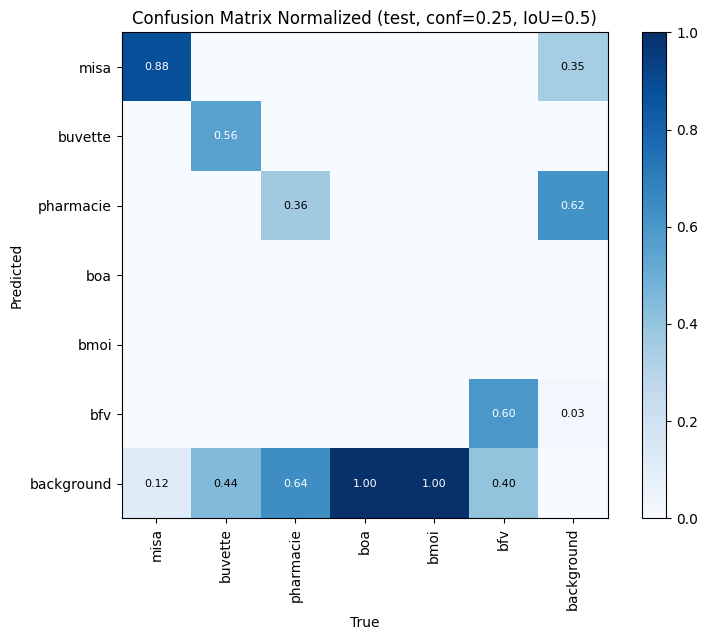

In [ ]:
# =====================================================================
#  Cellule à ajouter dans le notebook, APRÈS l'évaluation sur le test.
#  Calcule la matrice de confusion et les effectifs absolus TP / FP / FN
#  sur le jeu de TEST, à un seuil de confiance et un seuil d'IoU FIXÉS.
#  Elle affiche les lignes LaTeX à coller dans le tableau de la thèse
#  et enregistre une matrice de confusion normalisée (PNG).
# =====================================================================
import numpy as np
import yaml
import matplotlib.pyplot as plt
from pathlib import Path
from ultralytics import YOLO

DATA_YAML = "/content/drive/MyDrive/test_doctorat/univ_misa/dataset/data.yaml"
BEST      = "/content/drive/MyDrive/test_doctorat/univ_misa/dataset/result_07Oct2026/train-2/weights/best.pt" # "/content/runs/detect/train-2/weights/best.pt"
CONF      = 0.25   # seuil de confiance (point de fonctionnement), à citer dans la thèse
IOU_MATCH = 0.5    # seuil d'IoU pour associer une détection à une boîte de référence
IMGSZ     = 640
EXTS      = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}


# ---------- fonctions (numpy pur, sans dépendance à Ultralytics) ----------
def iou_matrix(a, b):
    """IoU entre a (n,4) et b (m,4), boîtes en xyxy. Retourne (n,m)."""
    a = np.asarray(a, dtype=float).reshape(-1, 4)
    b = np.asarray(b, dtype=float).reshape(-1, 4)
    x1 = np.maximum(a[:, None, 0], b[None, :, 0])
    y1 = np.maximum(a[:, None, 1], b[None, :, 1])
    x2 = np.minimum(a[:, None, 2], b[None, :, 2])
    y2 = np.minimum(a[:, None, 3], b[None, :, 3])
    inter = np.clip(x2 - x1, 0, None) * np.clip(y2 - y1, 0, None)
    area_a = (a[:, 2] - a[:, 0]) * (a[:, 3] - a[:, 1])
    area_b = (b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1])
    return inter / (area_a[:, None] + area_b[None, :] - inter + 1e-9)


def update_confusion(M, gt_cls, gt_box, pr_cls, pr_box, pr_conf, iou_thr):
    """Met à jour M (lignes = prédit, colonnes = vrai, dernier indice = fond)."""
    nc = M.shape[0] - 1
    n_gt, n_pr = len(gt_cls), len(pr_cls)
    matched = set()
    if n_gt and n_pr:
        iou = iou_matrix(gt_box, pr_box)                  # (n_gt, n_pr)
        for j in np.argsort(-np.asarray(pr_conf)):        # confiance décroissante
            cand = [(iou[i, j], i) for i in range(n_gt)
                    if i not in matched and iou[i, j] >= iou_thr]
            if cand:
                _, i = max(cand)
                matched.add(i)
                M[pr_cls[j], gt_cls[i]] += 1              # TP si même classe, confusion sinon
            else:
                M[pr_cls[j], nc] += 1                     # FP sur le fond
    else:
        for c in pr_cls:
            M[c, nc] += 1                                 # FP (aucune boîte de référence)
    for i, c in enumerate(gt_cls):
        if i not in matched:
            M[nc, c] += 1                                 # FN (objet manqué)


def labels_dir_from_images_dir(images_dir: Path):
    parts = list(images_dir.parts)
    for k, p in enumerate(parts):
        if p == "images":
            parts[k] = "labels"
            return Path(*parts)
    return images_dir.parent / "labels"


# ---------- données et modèle ----------
cfg = yaml.safe_load(open(DATA_YAML))
names = cfg["names"]
names = [names[i] for i in sorted(names)] if isinstance(names, dict) else list(names)
nc = len(names)

img_dir = Path(cfg["test"])
if not img_dir.is_absolute():
    img_dir = Path(cfg.get("path", "")) / img_dir
lbl_dir = labels_dir_from_images_dir(img_dir)

model = YOLO(BEST)
M = np.zeros((nc + 1, nc + 1), dtype=int)

images = sorted(p for p in img_dir.rglob("*") if p.suffix.lower() in EXTS)
print(f"{len(images)} images de test | conf={CONF} | IoU={IOU_MATCH}")

for img in images:
    r = model.predict(str(img), conf=CONF, imgsz=IMGSZ, verbose=False)[0]
    h, w = r.orig_shape
    gt_cls, gt_box = [], []
    lf = lbl_dir / (img.stem + ".txt")
    if lf.exists():
        for line in open(lf):
            v = line.split()
            if len(v) >= 5:
                c, x, y, bw, bh = int(v[0]), *map(float, v[1:5])
                gt_cls.append(c)
                gt_box.append([(x - bw / 2) * w, (y - bh / 2) * h,
                               (x + bw / 2) * w, (y + bh / 2) * h])
    pr_cls = r.boxes.cls.cpu().numpy().astype(int).tolist()
    pr_box = r.boxes.xyxy.cpu().numpy()
    pr_conf = r.boxes.conf.cpu().numpy()
    update_confusion(M, gt_cls, gt_box, pr_cls, pr_box, pr_conf, IOU_MATCH)

# ---------- effectifs absolus ----------
tp = np.diag(M)[:nc]
fp = M[:nc].sum(1) - tp            # détections de la classe c qui ne sont pas des c
fn = M[:, :nc].sum(0) - tp         # objets c non détectés comme c
fp_bg = M[:nc, nc]                 # dont FP sur le fond
fn_miss = M[nc, :nc]               # dont objets complètement manqués
ref = M[:, :nc].sum(0)             # nombre d'objets de référence par classe

print("\nMatrice de confusion (lignes = prédit, colonnes = vrai, dernier = fond) :")
print(M)
print("\nLignes LaTeX (Classe & Réf. & TP & FP & dont fond & FN & dont manqués) :")
for i, n in enumerate(names):
    print(f"\\texttt{{{n}}} & {ref[i]} & {tp[i]} & {fp[i]} & {fp_bg[i]} & {fn[i]} & {fn_miss[i]} \\\\")
print(f"\\textbf{{Total}} & {ref.sum()} & {tp.sum()} & {fp.sum()} & {fp_bg.sum()} & {fn.sum()} & {fn_miss.sum()} \\\\")

print("\nLignes LaTeX de la matrice absolue (une ligne par classe prédite) :")
for i, n in enumerate(names + ["fond"]):
    print(f"\\texttt{{{n}}} & " + " & ".join(str(v) for v in M[i]) + " \\\\")

# ---------- matrice normalisée (par colonne = classe réelle) ----------
col = M.sum(0, keepdims=True).astype(float)
Mn = np.divide(M, col, out=np.zeros_like(M, dtype=float), where=col > 0)
labels = names + ["background"]
fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(Mn, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(nc + 1)); ax.set_xticklabels(labels, rotation=90)
ax.set_yticks(range(nc + 1)); ax.set_yticklabels(labels)
ax.set_xlabel("True"); ax.set_ylabel("Predicted")
ax.set_title(f"Confusion Matrix Normalized (test, conf={CONF}, IoU={IOU_MATCH})")
for i in range(nc + 1):
    for j in range(nc + 1):
        if Mn[i, j] > 0:
            ax.text(j, i, f"{Mn[i, j]:.2f}", ha="center", va="center",
                    color="white" if Mn[i, j] > 0.5 else "black", fontsize=8)
fig.colorbar(im, ax=ax, fraction=0.046)
fig.tight_layout()
out_png = "/content/confusion_matrix_normalized_test_conf025.png"
fig.savefig(out_png, dpi=200)
print("\nFigure enregistrée :", out_png)

In [ ]:
%cd /content/runs/detect/train-2/weights/

[Errno 2] No such file or directory: '/content/runs/detect/train-2/weights/'
/content


In [ ]:
model = YOLO("best.pt")
model.export(format="tflite")

WARNING ⚠️ format='tflite' is deprecated as of 8.4.83 and has been replaced by the unified Google LiteRT format. Exporting format='litert' instead. See https://docs.ultralytics.com/integrations/litert
Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu130 CPU (Intel Xeon CPU @ 2.00GHz)
YOLOv10n summary (fused): 99 layers, 2,266,338 parameters, 0 gradients, 6.6 GFLOPs

PyTorch: starting from 'best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 10, 8400) (5.5 MB)

LiteRT: starting export with litert_torch 0.9.4...


(00:00) [START] LiteRT-Torch Convert

(00:00) [START] LiteRT-Torch Convert > Torch Export: serving_default

(00:01) [START] LiteRT-Torch Convert > Torch Export: serving_default > ExportedProgram Run Decompositions

/usr/lib/python3.13/copyreg.py:99: FutureWarning: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
  return cls.__new__(cls, *args)


...

(00:13) [ DONE] LiteRT-Torch Convert (+00:13)

(00:00) [START] Write Model to best.tflite

(00:00) [ DONE] Write Model to best.tflite (+00:00)

LiteRT: export success ✅ 13.2s, saved as 'best.tflite' (8.9 MB)

Export complete (13.7s)
Results saved to /content/runs/detect/train-2/weights/best.tflite
Predict:         yolo predict task=detect model=best.tflite imgsz=640 
Validate:        yolo val task=detect model=best.tflite imgsz=640 data=/content/drive/MyDrive/test_doctorat/univ_misa/dataset/data.yaml  
Visualize:       https://netron.app


'best.tflite'

In [ ]:
import locale
locale.getpreferredencoding = lambda: "UTF-8"

In [ ]:
!cp -r /content/runs/detect /content/drive/MyDrive/test_doctorat/univ_misa/dataset/result_07Oct2026

cp: cannot stat '/content/runs/detect': No such file or directory
